In [1]:
!pip install -q "datasets[audio]" transformers torchaudio librosa scikit-learn tqdm

In [2]:
import json
import numpy as np
from datasets import load_dataset, Audio
ds = load_dataset(
    "SpeechAntiSpoofingBenchmarks/ASVspoof2021_LA",
    split="test",
    streaming=True
)
ds = ds.cast_column("audio", Audio(sampling_rate=16000))

real_clips, fake_clips = [], []
codecs_list = []
N_PER_CLASS = 400
MAX_LEN = 16000 * 4

for item in ds:
    label = item["label"]
    meta = json.loads(item["notes"])

    wav = item["audio"]["array"]
    wav = wav[:MAX_LEN] if len(wav) > MAX_LEN else np.pad(wav, (0, MAX_LEN - len(wav)))

    if label == 0 and len(real_clips) < N_PER_CLASS:
        real_clips.append((wav.astype(np.float32), 0, meta.get("codec", "none")))
    elif label == 1 and len(fake_clips) < N_PER_CLASS:
        fake_clips.append((wav.astype(np.float32), 1, meta.get("codec", "none")))

    if len(real_clips) >= N_PER_CLASS and len(fake_clips) >= N_PER_CLASS:
        break

combined = real_clips + fake_clips
dataset_samples = [(wav, lbl) for wav, lbl, _ in combined]
sample_codecs   = [c for _, _, c in combined]

print(f"Loaded {len(real_clips)} Real (Bonafide) and {len(fake_clips)} Fake (Spoof) clips!")
print("Codecs captured from ASVspoof 2021 LA:", set(sample_codecs))

README.md:   0%|          | 0.00/3.67k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/24 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/24 [00:00<?, ?it/s]

Loaded 400 Real (Bonafide) and 400 Fake (Spoof) clips!
Codecs captured from ASVspoof 2021 LA: {'alaw', 'opus', 'g722', 'none', 'gsm', 'ulaw', 'pstn'}


In [3]:
import torch
import librosa
from tqdm import tqdm
from transformers import AutoFeatureExtractor, HubertModel

device = "cuda" if torch.cuda.is_available() else "cpu"
extractor = AutoFeatureExtractor.from_pretrained("facebook/hubert-base-ls960")
model = HubertModel.from_pretrained("facebook/hubert-base-ls960", output_hidden_states=True).to(device).eval()

def extract_all_three_features(wav, sr=16000):
    # 1. ACOUSTIC: MFCC + Spectral Centroid + RMS Energy
    mfcc = librosa.feature.mfcc(y=wav, sr=sr, n_mfcc=20)
    delta = librosa.feature.delta(mfcc)
    centroid = librosa.feature.spectral_centroid(y=wav, sr=sr)
    rms = librosa.feature.rms(y=wav)
    acoustic_handcrafted = np.concatenate([
        mfcc.mean(1), mfcc.std(1), delta.mean(1), centroid.mean(1), rms.std(1)
    ])

    # Run HuBERT to get Acoustic (Layer 2), Phonetic (Layer 6), and Semantic (Layer 12) views
    inputs = extractor(wav, sampling_rate=sr, return_tensors="pt", padding=True).to(device)
    with torch.no_grad():
        hidden = model(**inputs).hidden_states

        # Acoustic SSL (Early Layer 2)
        acoustic_ssl = hidden[2].mean(dim=1).squeeze(0).cpu().numpy()

        # 2. PHONETIC: Middle Layer 6 + frame-to-frame phoneme transition variability
        phonetic_ssl = hidden[6].mean(dim=1).squeeze(0).cpu().numpy()
        transition_smoothness = torch.norm(hidden[6][:, 1:, :] - hidden[6][:, :-1, :], dim=-1).std().item()

        # 3. SEMANTIC: Final Layer 12 (linguistic/contextual representation)
        semantic_ssl = hidden[12].mean(dim=1).squeeze(0).cpu().numpy()

    # Cross-View Consistency: Cosine similarity between Acoustic, Phonetic, and Semantic views
    cos_ac_ph = np.dot(acoustic_ssl, phonetic_ssl) / (np.linalg.norm(acoustic_ssl) * np.linalg.norm(phonetic_ssl) + 1e-8)
    cos_ph_sem = np.dot(phonetic_ssl, semantic_ssl) / (np.linalg.norm(phonetic_ssl) * np.linalg.norm(semantic_ssl) + 1e-8)
    cos_ac_sem = np.dot(acoustic_ssl, semantic_ssl) / (np.linalg.norm(acoustic_ssl) * np.linalg.norm(semantic_ssl) + 1e-8)

    return np.concatenate([
        acoustic_handcrafted,
        acoustic_ssl,
        phonetic_ssl,
        [transition_smoothness],
        semantic_ssl,
        [cos_ac_ph, cos_ph_sem, cos_ac_sem]
    ])

X, y = [], []
for wav, label in tqdm(dataset_samples, desc="Extracting Acoustic+Phonetic+Semantic"):
    X.append(extract_all_three_features(wav))
    y.append(label)

X = np.array(X, dtype=np.float32)
y = np.array(y)
print("Final Combined Feature Matrix Shape:", X.shape)

preprocessor_config.json:   0%|          | 0.00/213 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.39k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  378MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  378MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]



Extracting Acoustic+Phonetic+Semantic:   0%|          | 0/800 [00:00<?, ?it/s]

Extracting Acoustic+Phonetic+Semantic:   0%|          | 1/800 [01:17<17:06:30, 77.08s/it]

Extracting Acoustic+Phonetic+Semantic:   0%|          | 2/800 [01:18<7:17:04, 32.86s/it] 

Extracting Acoustic+Phonetic+Semantic:   0%|          | 3/800 [01:20<4:09:14, 18.76s/it]

Extracting Acoustic+Phonetic+Semantic:   0%|          | 4/800 [01:24<2:49:51, 12.80s/it]

Extracting Acoustic+Phonetic+Semantic:   1%|          | 5/800 [01:27<2:00:17,  9.08s/it]

Extracting Acoustic+Phonetic+Semantic:   1%|          | 6/800 [01:30<1:34:27,  7.14s/it]

Extracting Acoustic+Phonetic+Semantic:   1%|          | 7/800 [01:34<1:21:57,  6.20s/it]

Extracting Acoustic+Phonetic+Semantic:   1%|          | 8/800 [01:41<1:23:34,  6.33s/it]

Extracting Acoustic+Phonetic+Semantic:   1%|          | 9/800 [01:46<1:16:36,  5.81s/it]

Extracting Acoustic+Phonetic+Semantic:   1%|▏         | 10/800 [01:47<1:00:16,  4.58s/it]

Extracting Acou

Final Combined Feature Matrix Shape: (800, 2370)


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, roc_curve
from scipy.optimize import brentq
from scipy.interpolate import interp1d

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Fusion Classifier
clf = MLPClassifier(hidden_layer_sizes=(256, 64), max_iter=50, random_state=42)
clf.fit(X_train_scaled, y_train)

# Evaluate Real vs. Fake Detection
y_pred = clf.predict(X_test_scaled)
y_prob = clf.predict_proba(X_test_scaled)[:, 1]

# Compute Equal Error Rate (EER) for Dissertation Report
fpr, tpr, _ = roc_curve(y_test, y_prob, pos_label=1)
eer = brentq(lambda x: 1.0 - x - interp1d(fpr, tpr)(x), 0.0, 1.0) * 100

print(f"Test Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")
print(f"Equal Error Rate (EER): {eer:.2f}%\n")
print(classification_report(y_test, y_pred, target_names=["REAL (Bonafide)", "FAKE (Deepfake)"]))

def detect_audio_file(file_path):
    wav, _ = librosa.load(file_path, sr=16000, duration=4.0)
    wav = np.pad(wav, (0, max(0, 64000 - len(wav))))[:64000]
    feats = scaler.transform([extract_all_three_features(wav)])
    prob_fake = clf.predict_proba(feats)[0][1]
    verdict = "FAKE (Deepfake Audio)" if prob_fake >= 0.5 else "REAL (Authentic Human Audio)"
    print(f"File: {file_path} --> Prediction: {verdict} (Fake Probability: {prob_fake*100:.1f}%)")

Test Accuracy: 93.75%
Equal Error Rate (EER): 6.25%

                 precision    recall  f1-score   support

REAL (Bonafide)       0.94      0.94      0.94        80
FAKE (Deepfake)       0.94      0.94      0.94        80

       accuracy                           0.94       160
      macro avg       0.94      0.94      0.94       160
   weighted avg       0.94      0.94      0.94       160



In [5]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_curve
from scipy.optimize import brentq
from scipy.interpolate import interp1d

X_train, X_test, y_train, y_test, codecs_train, codecs_test = train_test_split(
    X, y, np.array(sample_codecs), test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

feature_views = {
    "1. Handcrafted Acoustic Only (MFCC+Spectral)": slice(0, 62),
    "2. Acoustic View (Handcrafted + HuBERT L2)":   slice(0, 830),
    "3. Phonetic View (HuBERT L6 + Transitions)":   slice(830, 1599),
    "4. Semantic View (HuBERT L12 Context)":        slice(1599, 2367),
    "5. Proposed Combined (Acoustic+Phonetic+Semantic+Consistency)": slice(0, 2370)
}

results = []
trained_models = {}

for name, sl in feature_views.items():
    model_v = MLPClassifier(hidden_layer_sizes=(256, 64), max_iter=300, early_stopping=True, random_state=42)
    model_v.fit(X_train_s[:, sl], y_train)

    preds = model_v.predict(X_test_s[:, sl])
    probs = model_v.predict_proba(X_test_s[:, sl])[:, 1]

    fpr, tpr, _ = roc_curve(y_test, probs, pos_label=1)
    eer = brentq(lambda x: 1.0 - x - interp1d(fpr, tpr)(x), 0.0, 1.0) * 100

    results.append({
        "Feature View": name,
        "Accuracy (%)": round(accuracy_score(y_test, preds) * 100, 2),
        "F1-Score (%)": round(f1_score(y_test, preds) * 100, 2),
        "EER (%) [Lower is Better]": round(eer, 2)
    })
    trained_models[name] = (model_v, sl)

df_results = pd.DataFrame(results)
display(df_results)

,Feature View,Accuracy (%),F1-Score (%),EER (%) [Lower is Better]
0,1. Handcrafted Acoustic Only (MFCC+Spectral),80.62,80.00,20.00
1,2. Acoustic View (Handcrafted + HuBERT L2),91.25,91.57,10.00
2,3. Phonetic View (HuBERT L6 + Transitions),90.00,90.00,10.00
3,4. Semantic View (HuBERT L12 Context),92.50,92.50,7.50
4,5. Proposed Combined (Acoustic+Phonetic+Semant...,91.88,91.93,8.75


Per-Codec Performance on ASVspoof 2021 LA:


,Communication Codec,Test Clips,Combined Detector Accuracy (%)
0,alaw,24,91.67
1,g722,17,82.35
2,gsm,23,95.65
3,none,26,92.31
4,opus,27,81.48
5,pstn,22,100.00
6,ulaw,21,100.00


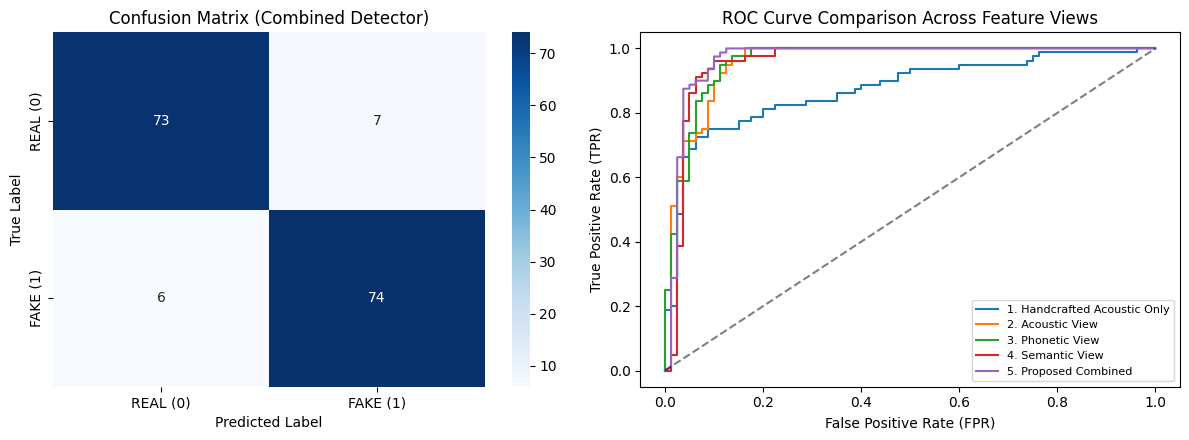

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

best_model, full_slice = trained_models["5. Proposed Combined (Acoustic+Phonetic+Semantic+Consistency)"]
y_pred_full = best_model.predict(X_test_s[:, full_slice])
y_prob_full = best_model.predict_proba(X_test_s[:, full_slice])[:, 1]

# 1. Per-Codec Accuracy Table (for Dissertation Chapter 4/5)
codec_rows = []
for codec_name in sorted(set(codecs_test)):
    mask = (codecs_test == codec_name)
    if mask.sum() >= 5:
        acc_c = accuracy_score(y_test[mask], y_pred_full[mask]) * 100
        codec_rows.append({
            "Communication Codec": codec_name,
            "Test Clips": int(mask.sum()),
            "Combined Detector Accuracy (%)": round(acc_c, 2)
        })

print("Per-Codec Performance on ASVspoof 2021 LA:")
display(pd.DataFrame(codec_rows))

# 2. Plot Confusion Matrix & ROC Curve side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

cm = confusion_matrix(y_test, y_pred_full)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["REAL (0)", "FAKE (1)"],
            yticklabels=["REAL (0)", "FAKE (1)"], ax=axes[0])
axes[0].set_title("Confusion Matrix (Combined Detector)")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

# ROC Comparison across Views
for name, (m, sl) in trained_models.items():
    p = m.predict_proba(X_test_s[:, sl])[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p, pos_label=1)
    short_name = name.split("(")[0].strip()
    axes[1].plot(fpr, tpr, label=short_name)

axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[1].set_title("ROC Curve Comparison Across Feature Views")
axes[1].set_xlabel("False Positive Rate (FPR)")
axes[1].set_ylabel("True Positive Rate (TPR)")
axes[1].legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig("dissertation_results_plot.png", dpi=300)
plt.show()

In [7]:
!pip install -q gradio
import joblib
import gradio as gr

# Save trained model and scaler so you don't have to retrain next time
# joblib.dump({"model": best_model, "scaler": scaler}, "deepfake_detector_asvspoof2021.pkl")
joblib.dump({
    "model": best_model,
    "scaler": scaler,
    "view_models": {
        "acoustic": trained_models["2. Acoustic View (Handcrafted + HuBERT L2)"][0],
        "phonetic": trained_models["3. Phonetic View (HuBERT L6 + Transitions)"][0],
        "semantic": trained_models["4. Semantic View (HuBERT L12 Context)"][0],
    }
}, "deepfake_detector_asvspoof2021.pkl")

def predict_for_ui(audio_filepath):
    if audio_filepath is None:
        return "Please upload or record an audio clip.", {}
    wav, _ = librosa.load(audio_filepath, sr=16000, duration=4.0)
    wav = np.pad(wav, (0, max(0, 64000 - len(wav))))[:64000]

    feat_vec = extract_all_three_features(wav)
    feat_scaled = scaler.transform([feat_vec])

    # Overall prediction from combined model
    prob_fake = float(best_model.predict_proba(feat_scaled)[0][1])
    prob_real = 1.0 - prob_fake
    verdict = "🚨 FAKE (Deepfake / Spoofed Speech)" if prob_fake >= 0.5 else "✅ REAL (Bonafide Human Speech)"

    # Individual view fake probabilities for explainability
    ac_m, ac_sl   = trained_models["2. Acoustic View (Handcrafted + HuBERT L2)"]
    ph_m, ph_sl   = trained_models["3. Phonetic View (HuBERT L6 + Transitions)"]
    sem_m, sem_sl = trained_models["4. Semantic View (HuBERT L12 Context)"]

    summary = (
        f"Final Verdict: {verdict}\n"
        f"• Acoustic View Fake Score: {ac_m.predict_proba(feat_scaled[:, ac_sl])[0][1]*100:.1f}%\n"
        f"• Phonetic View Fake Score: {ph_m.predict_proba(feat_scaled[:, ph_sl])[0][1]*100:.1f}%\n"
        f"• Semantic View Fake Score: {sem_m.predict_proba(feat_scaled[:, sem_sl])[0][1]*100:.1f}%"
    )
    return summary, {"REAL (Bonafide)": prob_real, "FAKE (Deepfake)": prob_fake}

demo = gr.Interface(
    fn=predict_for_ui,
    inputs=gr.Audio(type="filepath", label="Upload Audio or Record via Microphone"),
    outputs=[
        gr.Textbox(label="Detection Verdict & Multi-View Breakdown", lines=5),
        gr.Label(label="Confidence Probabilities")
    ],
    title="Deepfake Audio Detector (Acoustic + Phonetic + Semantic Fusion)",
    description="Trained on ASVspoof 2021 LA using HuBERT Multi-Layer + Handcrafted Acoustic Features"
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e669d6ef2079df9356.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
